<b>Задание</b>
1. Познакомьтесь с данными.
2. Добавьте информацию из датасета region.csv.
3. Восстановите пропуски в столбце kitchen_area. 
4. Исследуйте рынок недвижимости в РФ за представленный период. Величина исследования - цена за м2. Обработайте аномалии.
5. Когда выгодно покупать/продавать объект недвижимости? 
6. Определите от каких признаков зависит стоимость объекта недвижимости. Найдите скрытые закономерности.
7. Выдвинете и проверьте собственную гипотезу статистическими методами.
8. Создайте модель прогноза цены объекта недвижимости.

<h1 id="navigation">Навигация</h1>

 * [Данные](#first-bullet)
* [Пропуски и другие проблемы](#second-bullet)
* [Исследование рынка недвижимости](#third-bullet)
 * [Когда выгодно покупать/продавать объект недвижимости?](#forth-bullet)
 * [Анализ взаимосвязей](#fifth-bullet)
 * [Проверка гипотезы](#sixth-bullet)
 * [Прогноз цен на недвижимость](#seventh-bullet)

In [1]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st


import warnings
warnings.filterwarnings("ignore")

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

from IPython.display import display, HTML
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.metrics import  mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

#  Данные  <a class="anchor" id="first-bullet"></a>

Перед тем, как анализировать данные необходимо вникнуть в их суть и понять есть ли неприятности, с которыми надо разбираться. 

In [2]:
df = pd.read_csv('realty_18_21.csv')
df

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,81,3,13,14,2,60.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...
5477001,19739760,2021-05-01,3,1,8,17,4,93.2,13.8,11
5477002,12503160,2021-05-01,3,2,17,32,2,45.9,6.6,11
5477003,8800000,2021-05-01,2871,2,4,17,3,86.5,11.8,1
5477004,11831910,2021-05-01,3,1,8,33,2,52.1,18.9,11


In [3]:
regions =pd.read_csv('region.csv')
regions.columns = ['region','region_name']
regions['region'].unique() #.astype(int) преобразовать к числовому типу (чтобы объединить две таблицы на основе столбца
                           # не получилось сразу, т.к. есть проблема
regions.loc[regions['region'] == '7873, 6937'] # строка с индексом 36
                                               # для Республики Крым коды заданы списком,притом оба этих значения
                                               # фигурируют в нашем исходном датафрейме. Нужно убрать эту строку, 
                                               #чтобы перевести  все в числа, перед этим разделить ее на две записи. 
regions.loc[83] =  ['7873', 'Республика Крым']
regions.loc[84] =  ['6937', 'Республика Крым'] 
regions = regions.drop([36]).reset_index(drop=True)
regions['region'] = regions['region'].astype(int)
df = pd.merge(df, regions,on='region', how='outer')
df.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург


In [4]:
# df.info() - осталась только одна проблема - столбец date нужно представить как datetime64[ns], 
              # чтобы легче было работать с графиками  в будущем 
df['date'] = pd.to_datetime(df['date'])
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5477006 entries, 0 to 5477005
Data columns (total 11 columns):
 #   Column         Dtype         
---  ------         -----         
 0   price          int64         
 1   date           datetime64[ns]
 2   region         int64         
 3   building_type  int64         
 4   level          int64         
 5   levels         int64         
 6   rooms          int64         
 7   area           float64       
 8   kitchen_area   float64       
 9   object_type    int64         
 10  region_name    object        
dtypes: datetime64[ns](1), float64(2), int64(7), object(1)
memory usage: 459.6+ MB


In [5]:
# Для лучшей читаемости добавим столбец с отформатированными ценами 
df['price_f'] = df['price'].apply(lambda x: f"{x:,.0f}")
df.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург,"6,050,000"


### Удаляем дубликаты 

In [6]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

Неявные дубликаты в данных могут представлять собой ситуации повторной публикации объявления. Для первичного рынка ситуация с абсолютными дубликатами более вероятна, так как зачастую застройщики устанавливают стандартизованные цены на объекты, так как сами квартиры стандартны. НО для вторичного рынка такая ситуация не совсем логична, так как ооочень редко можно встретить абсолютно одтинаковые квартиры со всеми одинаковыми характеристиками по одинаковой цене. 
Процесс установления цен на рынке вторичной недвижимости является более случайным. Значит будем рассматривать только дубликаты на вторичном рынке. При этом не будем учитывать в признаках для дублирования дату, так как объявления могут размещаться в разное время

In [7]:
print(f"Размерность таблицы до удаления дубликатов: {df.shape}")

# Фильтруем только строки, где object_type == 1
df_secondary= df[df['object_type'] == 1]

# Удаляем дубликаты по выбранным столбцам только для этих строк
df_secondary = df_secondary.drop_duplicates(subset=['price', 'region', 'building_type', 'level', 'levels', 'rooms', 'area', 'object_type'])

# Теперь объединяем обратно с остальными данными (где object_type != 1)
df_primary = df[df['object_type'] != 1]

# Объединяем две части таблицы
df = pd.concat([df_secondary, df_primary])

# Выводим размерность таблицы до и после удаления дубликатов
print(f"Размерность таблицы после удаления дубликатов для вторичного рынка: {df.shape}")

Размерность таблицы до удаления дубликатов: (5241351, 12)
Размерность таблицы после удаления дубликатов для вторичного рынка: (4348568, 12)


<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px; font-weight: bold;">
ВЫВОДЫ:
    </div>
        
  -  Таблица содержит 5 477 006 строк и 11 столбцов, что говорит о большом объеме данных, подходящих для анализа недвижимости. Она содержит данные о недвижимости, в частности, о ценах, характеристиках объектов и региональной принадлежности
  - 7 столбцов имеют тип int64 
  - 2 столбца имеют тип float64 
  - 1 столбец имеет тип datetime64[ns] 
  - 1 столбец имеет тип object 
  - Удалено 892 783 дубликатов 

### [Вернуться к навигации](#Навигация)

## Пропуски и другие проблемы  <a class="anchor" id="second-bullet"></a>

In [8]:
df.isnull().sum()
# пропуски только в площади кухни

price                 0
date                  0
region                0
building_type         0
level                 0
levels                0
rooms                 0
area                  0
kitchen_area     207476
object_type           0
region_name           0
price_f               0
dtype: int64

## ДРУГИЕ ПРОБЛЕМЫ 
1. цена меньше нуля 
2. площадь кухни больше чем площадь общая
3. тип квартиры '-2'
4. этаж  квартиры выше чем этажей в доме 
5. малый метраж
6. слишком большой метраж
7. слишком низкая цена
8. слищшком высокая цена

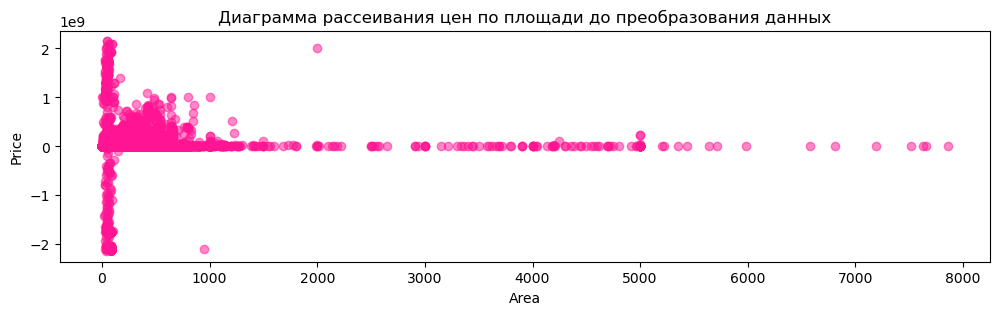

In [9]:
plt.figure(figsize=(12, 3))
plt.scatter(df['area'], df['price'], alpha=0.5, color ='deeppink')
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Диаграмма рассеивания цен по площади до преобразования данных')
plt.show()

### 1. Цена меньше нуля 

In [10]:
df[df['price'] <=  0]
df = df.drop(df[df['price'] <= 0].index).reset_index(drop=True) #лучше их удалить. Их не так много относительно объема датасета

### 2. Площадь кухни больше общей площади

In [11]:
df.loc[df['area'] < df['kitchen_area']] # вот это действительно очень странно. Удалять эти строки не хочется.
                                        # Предположу, что ошибка вызвана человеческим фактором. связана с невнимательностью. 
                                        # Если поменять местами значения столбцов в этой ситуации, такой расклад имеет значение.

df.loc[df['area'] < df['kitchen_area'], ['area', 'kitchen_area']] = df.loc[df['area'] < df['kitchen_area'],
                                                                           ['kitchen_area', 'area']].values


###  3. Комнат '-2'

In [12]:
print(df['rooms'].unique())
df.loc[df['rooms'] == -2, 'region_name'].describe()

[ 3  1  2  4 -1  5  6  7  8  9 -2 10]


count                 333
unique                 33
top       Санкт-Петербург
freq                  124
Name: region_name, dtype: object

Я полагаю, что '-2' это коммунальные квартиры. Наиболее часто такие объекты встречаются в Петербурге (треть из всех подобных объектов). Проанализировав рынок комнат в коммунальной квартире Петербурга выявлено, что максимальная площадь от 6 до 60 кв.м. а цена - от 450 тыс до 19 млн 

In [13]:
df.loc[(df['rooms'] == -2)& (df['area'] <= 60) & (df['price'] > 19000000), 'price'] = df.loc[(df['rooms'] == -2)& (df['area'] <= 60) & (df['price'] > 19000000), 'price'] / 10

#можем поделить цену на 10, это больше похоже на правду 

In [14]:
price_max = df.loc[(df['rooms'] == -2), 'price'].max()

In [15]:
df.query('rooms == -2 & price == @price_max') 

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f
1096564,871290000.0,2019-11-23,3,3,8,8,-2,519.1,30.0,1,Москва,"871,290,000"


In [16]:
area_left= df.loc[(df['rooms'] == -2) & (df['area'] > 60), 'area'].describe()
price_left = df.loc[(df['rooms'] == -2) & (df['area'] > 60), 'price'].describe()
pd.DataFrame({'area': area_left, 'price': price_left})

,area,price
count,159.000000,1.590000e+02
mean,315.459119,5.817986e+07
std,175.175261,8.824509e+07
min,60.100000,5.500000e+05
25%,189.500000,1.750000e+07
50%,285.000000,3.200000e+07
75%,399.000000,6.825000e+07
max,1000.000000,8.712900e+08


In [17]:
 # похоже, это двухкомнатные квартиры
df.loc[(df['rooms'] == -2)& (df['area'] > 60), 'rooms'] = 2

### 4. Этажей в доме меньше, чем этаж, на котором квартира

In [18]:
df.loc[df['level'] > df['levels']] # поступим так же как с площадью кухни - поменяем местами столбцы
df.loc[df['level'] > df['levels'], ['level', 'levels']] = df.loc[df['level'] > df['levels'],
                                                                           ['levels', 'level']].values
df.loc[df['level'] > df['levels']]


,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f


### 5. Малый метраж

Посмотрев все данные и увидев что в них представлены квартиры площадью менее 3 кв.м. я озадачилась вопросом реальности существования таких квартир. Они действительно существуют, но их площадь начинается от 3 квадратных метров

In [19]:
df.loc[(df['area'] < 3),'rooms'].describe()

count    231.000000
mean       0.536797
std        1.207652
min       -1.000000
25%       -1.000000
50%        1.000000
75%        1.000000
max        5.000000
Name: rooms, dtype: float64

In [20]:
df.loc[(df['area'] <= 3)&(df['rooms'] == 5)] #это что-то странное, просто уберем 
df = df.loc[~((df['area'] <= 3) & (df['rooms'] == 5))]

In [21]:
df.loc[(df['area'] < 1)] # тут по ценам похоже, что в табличном редакторе установился процентный формат столбца с ценой 
df.loc[df['area'] < 1, 'area'] *= 100

In [22]:
df.loc[(df['area'] < 3),'rooms'].describe()

count    216.000000
mean       0.425926
std        1.080084
min       -1.000000
25%       -1.000000
50%        1.000000
75%        1.000000
max        3.000000
Name: rooms, dtype: float64

In [23]:
df.loc[(df['area'] <= 3)&(df['rooms'] == 3)& (df['price'] > 1000000),'area'] *= 100
df.loc[(df['area'] <= 3)&(df['rooms'] == 3)] # по данным сайтов по продаже недвиимости в Хакасии можно купить 2 и 3 комнатную квартиру метражом более 20 м за такую цену 
df.loc[df['area'] <= 3, 'area'] *=10

### 6. Слишком большой метраж

In [24]:
df[df['area'] > 1000] # поделим на 100 метраж, по ценам похоже, что введен лишний 0
df.loc[df['area'] >= 1000, 'area'] = df.loc[df['area'] >= 1000, 'area'] / 100

In [25]:
df['area'].describe()

count    4.348266e+06
mean     5.439704e+01
std      2.646055e+01
min      3.020000e+00
25%      3.840000e+01
50%      4.900000e+01
75%      6.400000e+01
max      9.999900e+02
Name: area, dtype: float64

<Axes: >

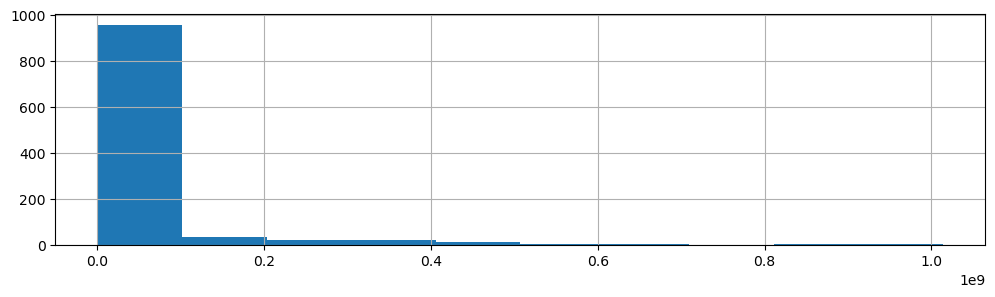

In [26]:
plt.figure(figsize=(12, 3))
df.loc[df['area'] > 500, 'price'].hist() # в 100 млн 

## 7. Слижком низкая цена

In [27]:
df = df[~(df['price'] < 100000)]
df = df.loc[~((df['price'] < 1000000) & (df['area'] <= 100) & (df['rooms'] != -2))]
# df = df.loc[~((df['area'] >= 200) & (df['price'] >= 10000000) & (df['price'] < 100000000))]
df = df.loc[~((df['area'] > 300) & (df['price'] < 20000000))]
df = df.loc[~((df['rooms'] != -2) & (df['price'] < 1000000))]
# df = df.loc[~((df['area'] > 200) & (df['price'] < 10000000))]
df = df.loc[~((df['area'] > 700) & (df['price'] < 100000000))]

Честно, я не могу объяснить почему я преобразовывала данные именно так. Не хотелось удалять, а исходя из логических соображений должно было получиться что-то такое. Решила рассмотреть все подозрительные случаи в отдельности.

UPDATE я все-таки решила их удалить. Изначально не совсем корректно поняла задание, и посчитала, что ошибки в данных связаны с ошибками формата данных в табличном редакторе, в котором они хранятся. Но если я правильно понимаю, то эти записи представлят собой объявления на сайтах. В таком случае действительно могут быть такие ситуации -некоторые продавцы ставят цены по типу 1р, 100р хотя квартира конечно стоит в разы дороже - и лучше их просто удалить. Данных и так слишком много

## 8. Слижком большая цена

In [28]:
df = df.loc[~((df['price'] >= 1000000000) &(df['area'] > 50)& (df['area'] < 1000))]
df = df.loc[~((df['price'] >= 1000000000)& (df['area'] < 50))]

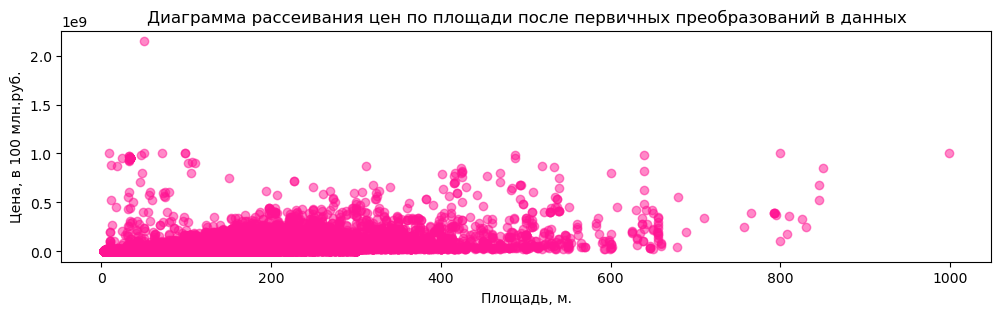

In [29]:
plt.figure(figsize=(12, 3))
plt.scatter(df['area'], df['price'], alpha=0.5, color ='deeppink')
plt.xlabel('Площадь, м.')
plt.ylabel('Цена, в 100 млн.руб.')
plt.title('Диаграмма рассеивания цен по площади после первичных преобразований в данных')
plt.show()

## ПРОПУСКИ

Для заполнения пропусков используем алгоритм **<span style="color:deeppink;">MICE (Multiple Imputation by Chained Equations) </span>**

В наборе данных есть пропуски в столбце kitchen_area, и  MICE может использовать корреляцию с другими признаками, чтобы адекватно предсказать значения пропусков. Я отдельно выделила датасет **df_selected**, в который поместила только `kitchen_area` и `area`, таким образом алгоритм будет использовать зависимость между площадью кухни зависит от общей площадью квартиры 

In [30]:
kitchen_before = round(df['kitchen_area'].mean(), 2)
std_before = round(df['kitchen_area'].std(),2)

In [31]:
df_selected = df[['kitchen_area']]
mice = df_selected
scaler = StandardScaler()

mice = pd.DataFrame(scaler.fit_transform(mice), columns = ['kitchen_area'])

mice_imputer = IterativeImputer(initial_strategy = 'mean', # вначале заполним пропуски средним значением
                                estimator = LinearRegression(), # в качестве модели используем линейную регрессию
                                random_state = 42 # добавим точку отсчета
                                )
mice = mice_imputer.fit_transform(mice)

mice = pd.DataFrame(scaler.inverse_transform(mice), columns = ['kitchen_area'])
mice.kitchen_area = mice.kitchen_area

df['kitchen_area'] =  mice['kitchen_area'].values
df.isnull().sum()

price            0
date             0
region           0
building_type    0
level            0
levels           0
rooms            0
area             0
kitchen_area     0
object_type      0
region_name      0
price_f          0
dtype: int64

In [32]:
kitchen_after = round(df['kitchen_area'].mean(), 2)
std_after = round(df['kitchen_area'].std(), 2)

print(f'Значения до заполнения пропусков через Mice: \n средняя площадь кухни {kitchen_before} \n СКО {std_before}')
print(f'Значения после заполнения пропусков через Mice: \n средняя площадь кухни {kitchen_after} \n СКО {std_after}')

Значения до заполнения пропусков через Mice: 
 средняя площадь кухни 11.01 
 СКО 6.21
Значения после заполнения пропусков через Mice: 
 средняя площадь кухни 11.01 
 СКО 6.06


- https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html 
- https://www.dmitrymakarov.ru/data-analysis/nan-06-2/

<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px; font-weight: bold;">
ВЫВОДЫ:
    </div>

## [Вернуться к навигации](#Навигация)

##  Исследование рынка недвижимости  <a class="anchor" id="third-bullet"></a>



In [33]:
df['price_f'] = df['price'].apply(lambda x: f"{x:,.0f}")
df['price_per_m'] = (df['price'] / df['area']).round(1)
df.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f,price_per_m
0,6050000.0,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург,"6,050,000",73244.6


In [34]:
df = df[~(df['price_per_m'] > 1000000)]
df = df[df['price_per_m'] >= 10000]
df.shape

(4220391, 13)

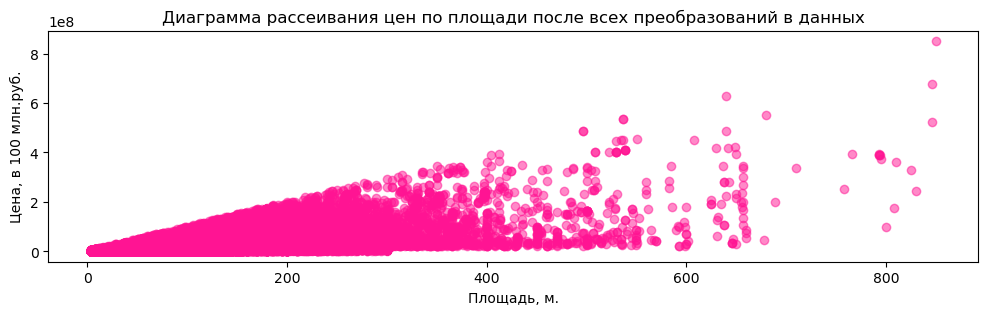

In [35]:
plt.figure(figsize=(12, 3))
plt.scatter(df['area'], df['price'], alpha=0.5, color ='deeppink')
plt.xlabel('Площадь, м.')
plt.ylabel('Цена, в 100 млн.руб.')
plt.title('Диаграмма рассеивания цен по площади после всех преобразований в данных')
plt.show()

In [36]:
df['price_per_m'].describe().apply(lambda x: '{:,.2f}'.format(x))

count    4,220,391.00
mean        84,354.88
std         63,529.89
min         10,000.00
25%         46,451.60
50%         65,306.10
75%        100,000.00
max      1,000,000.00
Name: price_per_m, dtype: object

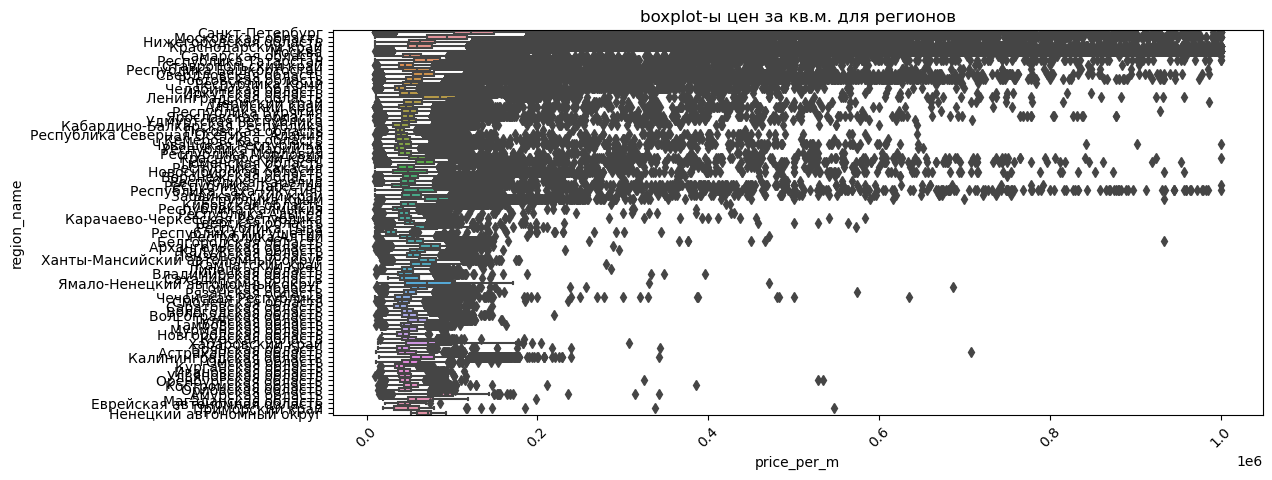

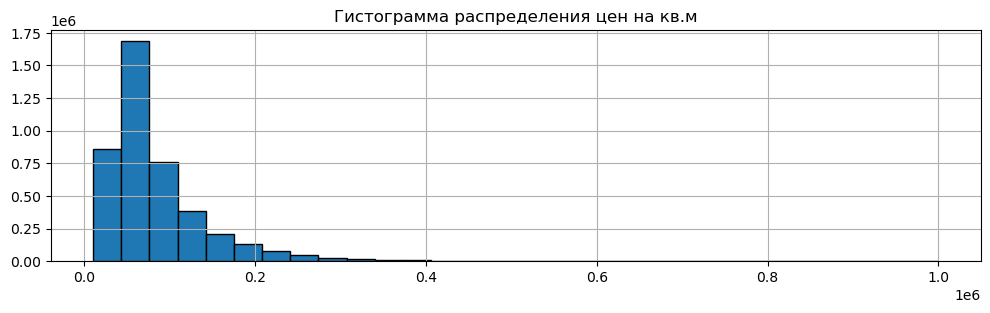

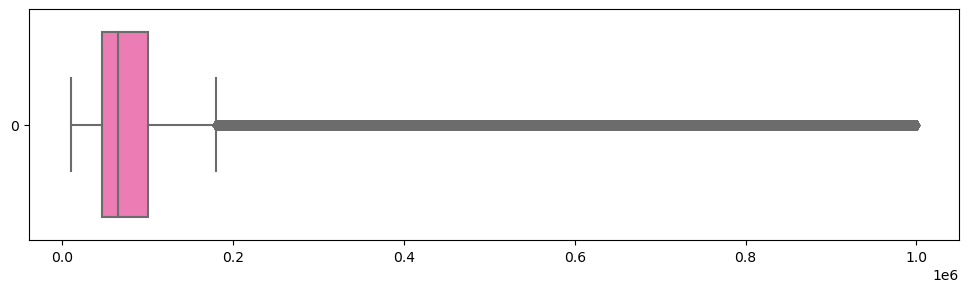

In [37]:
plt.figure(figsize=(12, 5))
sns.boxplot(x='price_per_m', y='region_name', data=df, orient = "h")
plt.xticks(rotation=45)
plt.title('boxplot-ы цен за кв.м. для регионов')
plt.show()

# красота - можно сказать, что в целом данные достаточно однородные, в больших городах заметно, что "выбросов" гораздо больше

plt.figure(figsize=(12, 3))
df['price_per_m'].hist(bins=30, edgecolor='black')
plt.title('Гистограмма распределения цен на кв.м')
plt.show()

plt.figure(figsize=(12, 3))
sns.boxplot(df['price_per_m'], orient="h",color = 'hotpink')
plt.show()

In [38]:
df['price_per_m'].describe().apply(lambda x: '{:,.2f}'.format(x))

count    4,220,391.00
mean        84,354.88
std         63,529.89
min         10,000.00
25%         46,451.60
50%         65,306.10
75%        100,000.00
max      1,000,000.00
Name: price_per_m, dtype: object

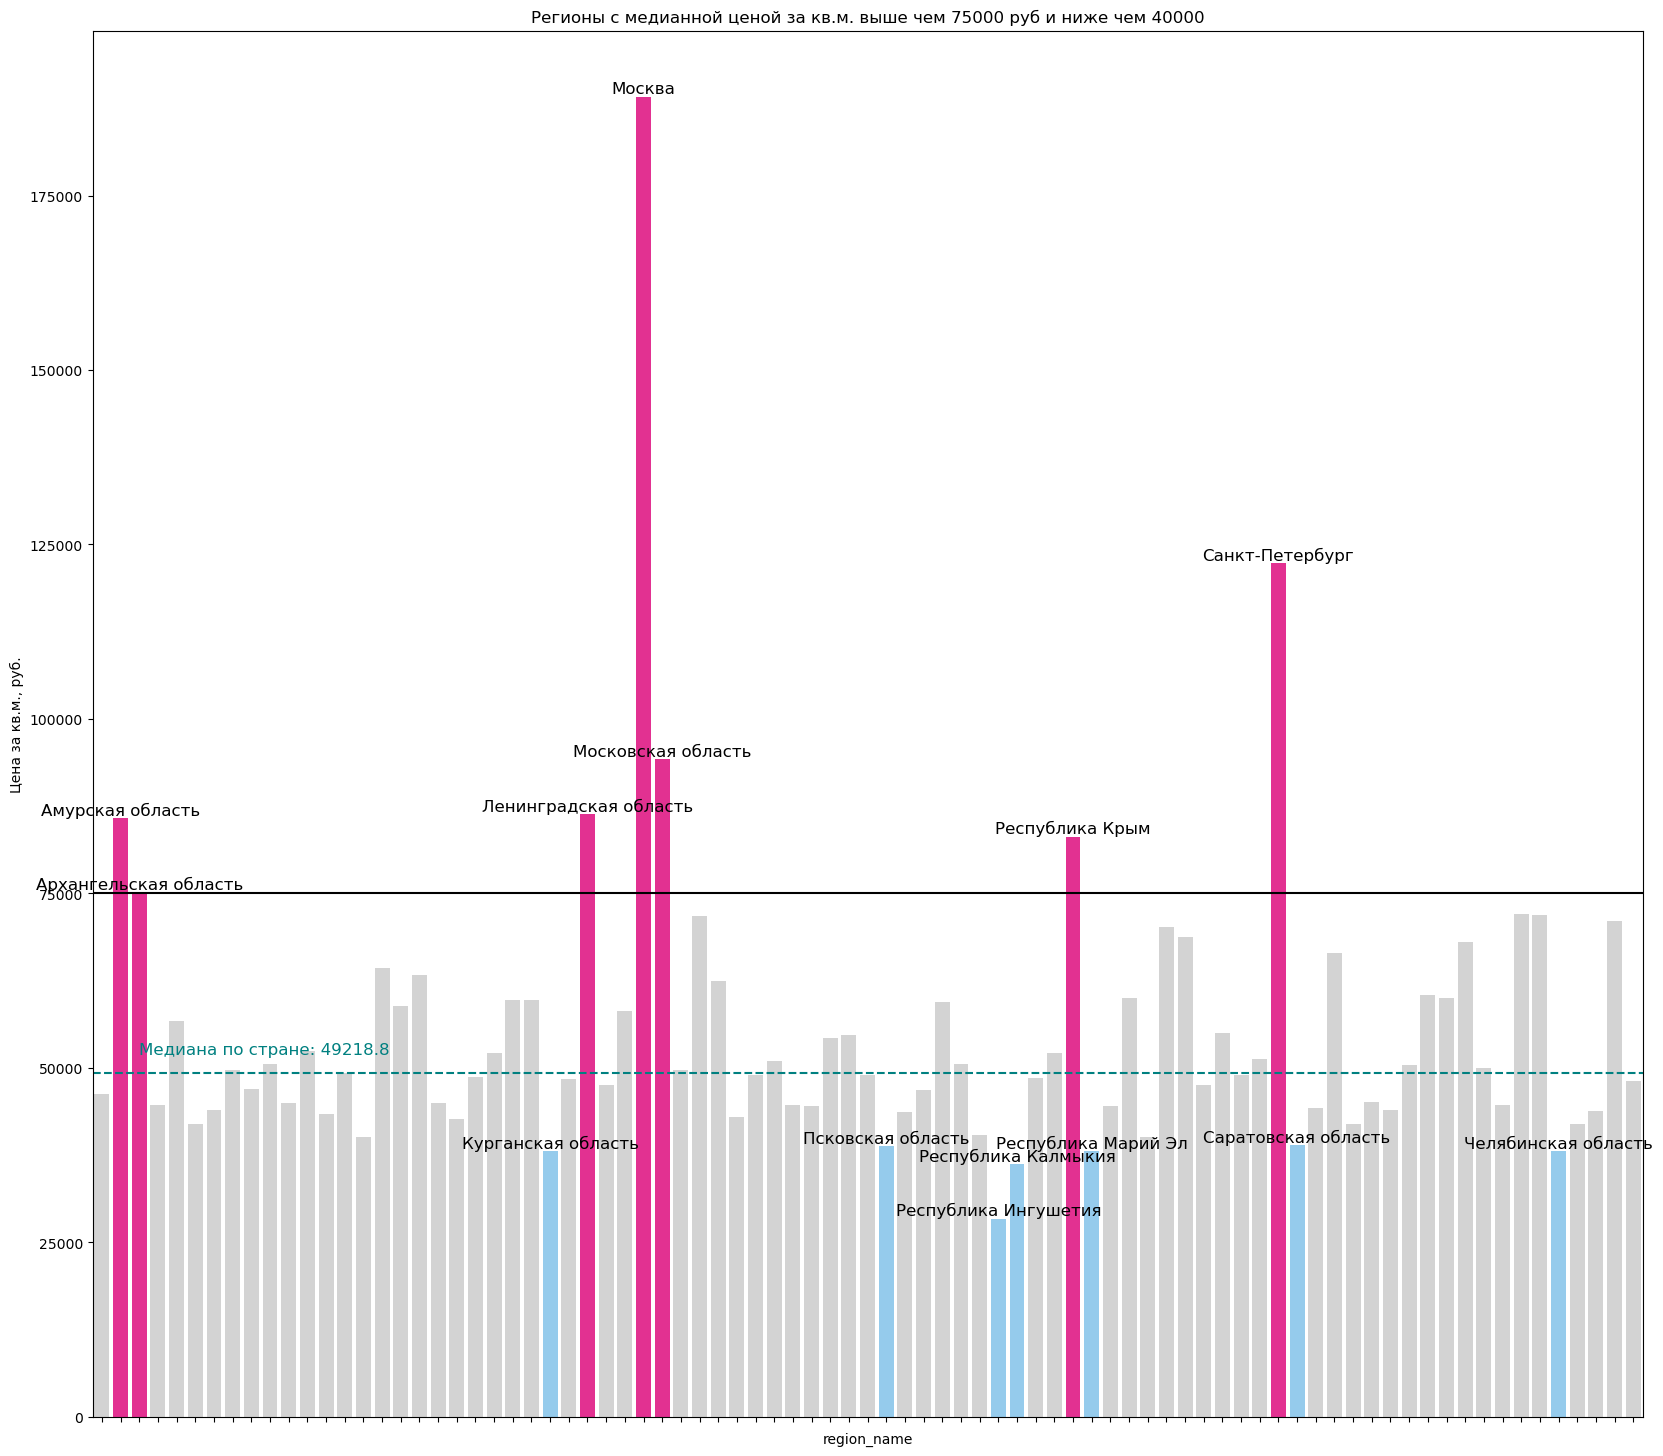

In [39]:
df_grouped = pd.DataFrame(df.groupby('region_name')['price_per_m'].median()).reset_index()


plt.figure(figsize=(20, 18))

def get_color(price): # создадим функцию, которая позволит выделить цветами нужные группы 
    if price > 75000: 
        return 'deeppink'
    elif price < 40000:
        return 'lightskyblue'
    else:
        return 'lightgray'

df_grouped['color'] = df_grouped['price_per_m'].apply(get_color)

ax = sns.barplot(data=df_grouped, x='region_name', y='price_per_m', palette=df_grouped['color'])

regions_high= df_grouped[df_grouped['price_per_m'] > 75000] # выберем регионы, сильно отличающиеся по цене (причем берем 
                                                            # не 3 квантиль, а 75000 - так получится нагляднее, я проверяла)

for idx, row in regions_high.iterrows(): # подпишем эти регионы на графике, так как это будет нагляднее (из-за того, 
                                         # что регионов очень много они наслаиваются друг на друга и ничего не понятно )
    ax.text(idx, row['price_per_m'], row['region_name'], ha='center', va='bottom', fontsize=12, color='black')

plt.axhline(y=75000, color='black')

regions_low= df_grouped[df_grouped['price_per_m'] < 40000]

for idx, row in regions_low.iterrows():
    ax.text(idx, row['price_per_m'], row['region_name'], ha='center', va='bottom', fontsize=12, color='black')

median_value = df_grouped['price_per_m'].median()
ax.axhline(y=median_value, color='teal', linestyle='--', label=f'Median: {median_value}')
ax.text(x=2, y=52000, s=f'Медиана по стране: {median_value}', color='teal', fontsize=12, ha='left')

ax.set_xticklabels([])
plt.title("Регионы с медианной ценой за кв.м. выше чем 75000 руб и ниже чем 40000")
plt.ylabel('Цена за кв.м., руб.')

plt.show()

<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px; font-weight: bold;">
ВЫВОДЫ:
    </div>
    
    Наблюдается значительное расхождение в ценах между регионами. Москва и Московская область демонстрируют значительно более высокие медианные цены, чем другие регионы, существенно превышающие среднюю по стране. Санкт-Петербург также характеризуется более высокой ценой, чем большинство регионов. Большинство остальных регионов имеют медианные цены, близкие к общероссийскому среднему значению или ниже его. Визуально выделяется значительная неоднородность цен по регионам России

## [Вернуться к навигации](#Навигация)

##  Когда выгодно покупать/продавать объект недвижимости?  <a class="anchor" id="forth-bullet"></a>

In [40]:
df['month'] = df['date'].dt.month

months = {
     1: 'Январь',
    2: 'Февраль',
    3: 'Март',
    4: 'Апрель',
    5: 'Май',
    6: 'Июнь',
    7: 'Июль',
    8: 'Август',
    9: 'Сентябрь',
    10: 'Октябрь',
    11: 'Ноябрь',
    12: 'Декабрь'}

df['month_name'] = df['month'].map(months)

Покупать выгодно когда цена ниже, а продавать - когда выше. Найдем топ месяцев для обоих случаев по стране и в крупнейших городах Росии для большей информативности. Сравнивать будем так же по цене за квадратный метр, это более репрезентативно 

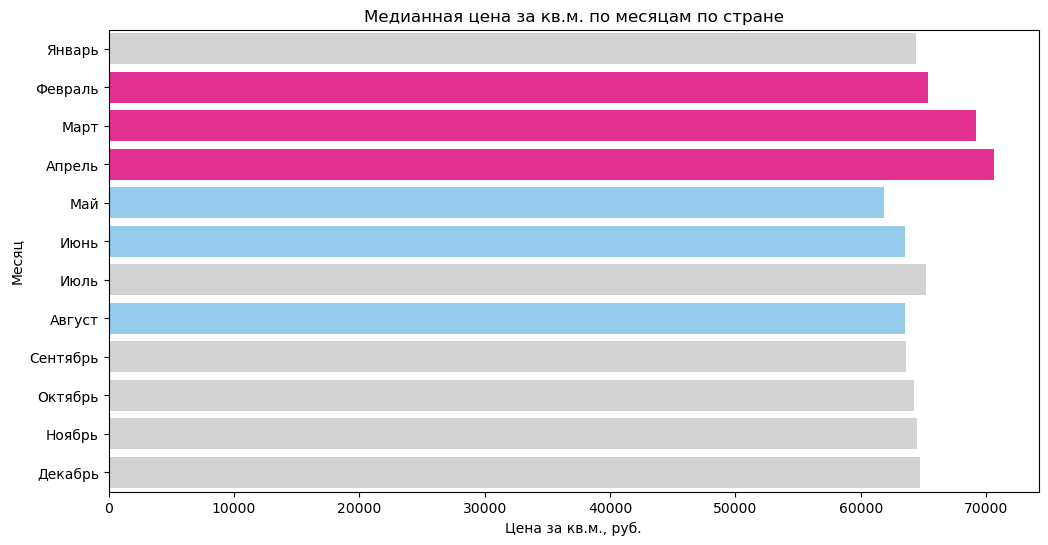

In [41]:
rus_median_price_months = pd.DataFrame(df.groupby('month_name')['price_per_m'].agg('median')).reset_index()

def get_color(price):
    if price > rus_median_price_months['price_per_m'].describe()['75%']:
        return 'deeppink'
    elif price < rus_median_price_months['price_per_m'].describe()['25%']:
        return 'lightskyblue'
    else:
        return 'lightgray'

month_order = ['Январь', 'Февраль', 'Март', 'Апрель', 'Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь', 'Ноябрь', 'Декабрь']   
rus_median_price_months['month_name'] = pd.Categorical(rus_median_price_months['month_name'], categories=month_order, ordered=True)
rus_median_price_months = rus_median_price_months.sort_values('month_name')

rus_median_price_months['color'] = rus_median_price_months['price_per_m'].apply(get_color)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=rus_median_price_months, x='price_per_m', y='month_name', palette=rus_median_price_months['color'], orient = "h");

display(HTML("""
<p>  Месяцы, выгодные для <b style="color: lightblue;">покупки</b> недвижимости, выделены голубым цветом, 
    а месяцы для <b style="color: deeppink;">продажи</b> — розовым.
</p>
"""))

plt.title("Медианная цена за кв.м. по месяцам по стране")
plt.xlabel('Цена за кв.м., руб.')
plt.ylabel('Месяц')

plt.show();

In [42]:
# создадим датасет с медианными ценами за месяц для ВСЕХ регионов страны
cities_months_median_price  = pd.pivot_table(df,
                                            index = 'region_name',
                                            columns = 'month_name',
                                            values = 'price_per_m',
                                            aggfunc = 'median').round(1)

# мне захотелось посмотреть на размах цен в течение года, чтобы найти топ регионов с максимально нестаблильным или наоборот
# стабильным рынком недвижимости 
cities_months_median_price['max_min_diff'] = cities_months_median_price.max(axis=1) - cities_months_median_price.min(axis=1)

def highlight(row):
    data_to_style = row.iloc[:-1]
    colors = ['background-color: lightblue' if val == data_to_style.min() else
              'background-color: deeppink' if val == data_to_style.max() else
              '' for val in row]
    return colors

max_df = cities_months_median_price.sort_values(by ='max_min_diff', ascending = False).round(1).head()
styled_max_df = max_df.style.apply(highlight, axis=1)

min_df = cities_months_median_price.sort_values(by ='max_min_diff', ascending = True).round(1).head()
styled_min_df = min_df.style.apply(highlight, axis=1)

display(HTML("""
<p>  Месяцы, выгодные для <b style="color: lightblue;">покупки</b> недвижимости, выделены голубым цветом, 
    а месяцы для <b style="color: deeppink;">продажи</b> — розовым.
</p>
"""))
title_1 = 'ТОП-5 регионов с наибольшим размахом цен за кв.м в течение года'
display(HTML(f"<h3 style='text-align: center; color: black;'>{title_1}</h3>"))
display(styled_max_df)

title_2 = 'ТОП-5 регионов с наименьшим размахом цен за кв.м в течение года'
display(HTML(f"<h3 style='text-align: center; color: black;'>{title_2}</h3>"))
display(styled_min_df)


month_name,Август,Апрель,Декабрь,Июль,Июнь,Май,Март,Ноябрь,Октябрь,Сентябрь,Февраль,Январь,max_min_diff
region_name,,,,,,,,,,,,,
Приморский край,64202.300000,48067.600000,50193.100000,32407.400000,297511.600000,53953.300000,nan,45846.400000,51470.600000,195334.000000,nan,31177.600000,266334.000000
Сахалинская область,nan,nan,44210.500000,144444.400000,nan,nan,nan,32301.600000,135416.700000,nan,nan,nan,112142.800000
Ямало-Ненецкий автономный округ,62768.000000,109154.900000,65075.800000,88694.000000,111401.000000,92592.600000,86197.900000,70252.900000,70446.700000,53799.800000,63394.000000,118181.800000,64382.000000
Магаданская область,84798.100000,88088.800000,51769.300000,57142.900000,50000.000000,47619.000000,60192.200000,51974.400000,63460.300000,68965.500000,77319.600000,nan,40469.800000
Камчатский край,69555.000000,77267.600000,62686.600000,74468.100000,47166.600000,54098.400000,64814.800000,61673.300000,63663.700000,81531.800000,64648.200000,64724.900000,34365.200000


month_name,Август,Апрель,Декабрь,Июль,Июнь,Май,Март,Ноябрь,Октябрь,Сентябрь,Февраль,Январь,max_min_diff
region_name,,,,,,,,,,,,,
Кабардино-Балкарская Республика,40000.000000,41082.200000,40082.000000,40725.500000,40000.000000,39325.800000,40331.200000,39784.300000,40476.200000,39250.700000,40000.000000,40678.800000,1831.500000
Республика Мордовия,45000.000000,46116.500000,44665.200000,43841.600000,44474.400000,44478.500000,45887.400000,43988.300000,44047.600000,43761.000000,45151.500000,44106.000000,2355.500000
Псковская область,38815.800000,40188.700000,38690.000000,38524.600000,38888.900000,38683.200000,39314.000000,38981.900000,38888.900000,38419.200000,38095.200000,37819.000000,2369.700000
Республика Калмыкия,35665.400000,37146.000000,36585.400000,35200.000000,35814.000000,35170.700000,37688.000000,35865.000000,36167.300000,36498.400000,36585.400000,35802.500000,2517.300000
Республика Марий Эл,36998.700000,39130.400000,37798.200000,37524.800000,38807.400000,37940.400000,39534.900000,37209.300000,37605.600000,37564.100000,38333.300000,37714.300000,2536.200000


In [43]:
# найдем регионы, лидирующие по продажам 
sales_leaders = df.value_counts('region_name').head()
display(HTML(f"<h3>Регионы-лидеры продаж</h3>"))
display(sales_leaders)

sales_outsiders = df.value_counts('region_name').tail()
display(HTML(f"<h3>Регионы-аутсайдеры</h3>"))
display(sales_outsiders)

region_name
Новосибирская область    591981
Краснодарский край       474176
Санкт-Петербург          429061
Московская область       420627
Москва                   395450
Name: count, dtype: int64

region_name
Магаданская область             121
Еврейская автономная область     69
Приморский край                  57
Сахалинская область               9
Ненецкий автономный округ         5
Name: count, dtype: int64

In [44]:
sales_leaders_styled = cities_months_median_price.round(1).loc[sales_leaders.index].style.apply(highlight, axis=1)

display(HTML("""
<p>  Месяцы, выгодные для <b style="color: lightblue;">покупки</b> недвижимости, выделены голубым цветом, 
    а месяцы для <b style="color: deeppink;">продажи</b> — розовым.
</p>
"""))
title = 'Годовые цены за кв.м в течение года в ТОП-5 регионах лидерах продаж'
display(HTML(f"<h3 style='text-align: center; color: black;'>{title}</h3>"))
display(sales_leaders_styled)

month_name,Август,Апрель,Декабрь,Июль,Июнь,Май,Март,Ноябрь,Октябрь,Сентябрь,Февраль,Январь,max_min_diff
region_name,,,,,,,,,,,,,
Новосибирская область,45189.500000,60526.300000,50000.000000,41666.700000,38286.200000,36848.800000,58108.100000,53648.900000,51219.500000,41931.400000,53086.400000,45927.400000,23677.500000
Краснодарский край,59677.400000,63750.000000,58146.100000,60227.300000,59523.800000,60243.600000,61777.000000,57967.000000,57142.900000,57662.300000,61255.700000,60130.600000,6607.100000
Санкт-Петербург,120000.000000,136986.300000,119836.800000,121904.800000,119000.000000,120396.600000,126721.800000,120481.900000,119000.000000,117429.200000,123090.200000,119540.200000,19557.100000
Московская область,92307.700000,103899.700000,99613.700000,96491.200000,90400.200000,91210.600000,101200.000000,91698.100000,89800.000000,87837.800000,94597.100000,93928.800000,16061.900000
Москва,188606.000000,206725.200000,183035.700000,189781.000000,183700.000000,187000.000000,200265.300000,184841.300000,184500.000000,182370.800000,197826.100000,183078.500000,24354.400000


<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px; font-weight: bold;">
ВЫВОДЫ:
    </div>
    
    - Наиболее выгодными для продажи недвижимости являются Февраль, Март и Апрель
    - Для покупки недвижимости в среднем более выгодными представляются Май, Июнь, Август
    
    - Лидером продаж недвижимости, как ни странно, является Новосибирская облась, за ней - Краснодарский край, МО, Санкт-Петербург и только затем Москва. Во всех этих городах наиболее выгодным для продажи является Апрель, для покупки - Май, Октябрь и Сентябрь 
    - Наиболее отстающими регионами за период стали Магаданская область, Еврейская автономная область, Приморский край, Сахалинская область, Ненецкий автономный округ


## [Вернуться к навигации](#Навигация)

##  Анализ взаимосвязей  <a class="anchor" id="fifth-bullet"></a>

In [45]:
df = df.reset_index(drop=True) 
df.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f,price_per_m,month,month_name
0,6050000.0,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург,"6,050,000",73244.6,2,Февраль


Цена недвижимости может быть зависима от следующих факторов:
- тип здания
- количество этажей в доме
- этаж на котором расположена квартира
- количество комнат
- общая площадь 
- тип дома - новостройка/вторичка

Как мы уже выяснили, цена зависит также от месяца покупки И от региона покупки! Но мы не можем просто включить номер региона из столбца `region`, этот параметр ничего не показывает, а лишь является иной записью региона. Нужно придумать что-то другое!

Скачаем дополнительный датасет о количестве населения в регионах россии, чтобы проранжировать регионы по этому показателю . Это тоже влияет на стоимость жилья. Ссылка на датасет (данные 2021 года): https://data.rcsi.science/data-catalog/datasets/160/

In [46]:
population = pd.read_csv('data_population.csv')
population = pd.pivot_table(population,
                            index='region',
                            values='population',
                            aggfunc='sum').reset_index()

# Сортируем по населению и добавляем столбец с рангом
population = population.sort_values(by='population', ascending=False).reset_index(drop=True)
population = population.reset_index().rename(columns={'index': 'region_population_rank', 'region': 'region_name'})
population = population.set_index('region_name')

# при простом заполнении тут возникнет проблема - написание некоторых регионов в таблицах отличается. 
# Поменяем в таблице population индексы
population.rename(index={'Удмуртская республика':'Удмуртская Республика',
                         'Кабардино-Балкарская республика': 'Кабардино-Балкарская Республика',
                         'Республика Северная Осетия - Алания': 'Республика Северная Осетия — Алания',
                         'Чувашская республика':'Чувашская Республика',
                         'Карачаево-Черкесская республика':'Карачаево-Черкесская Республика',
                         'Ханты-Мансийский автономный округ - Югра':'Ханты-Мансийский автономный округ',
                         'Чеченская республика':'Чеченская Республика'
                        }, inplace=True) 

df['region_population_rank'] = df['region_name'].map(population['region_population_rank']) 
df.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,region_name,price_f,price_per_m,month,month_name,region_population_rank
0,6050000.0,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург,"6,050,000",73244.6,2,Февраль,3


In [47]:
df_numeric = df[['price', 'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'object_type', 'region_population_rank']]
df_numeric.head(1)

,price,building_type,level,levels,rooms,area,kitchen_area,object_type,region_population_rank
0,6050000.0,1,8,10,3,82.6,10.8,1,3


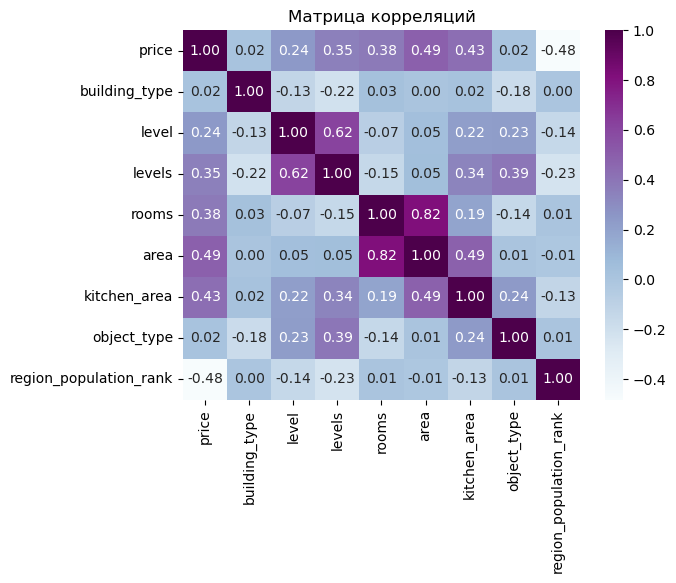

In [48]:
colors_palette = LinearSegmentedColormap.from_list("custom", ["lightblue", "deeppink"])

sns.heatmap(df_numeric.corr('spearman'), annot=True, fmt=".2f", cmap='BuPu')
plt.title("Матрица корреляций")
plt.show()

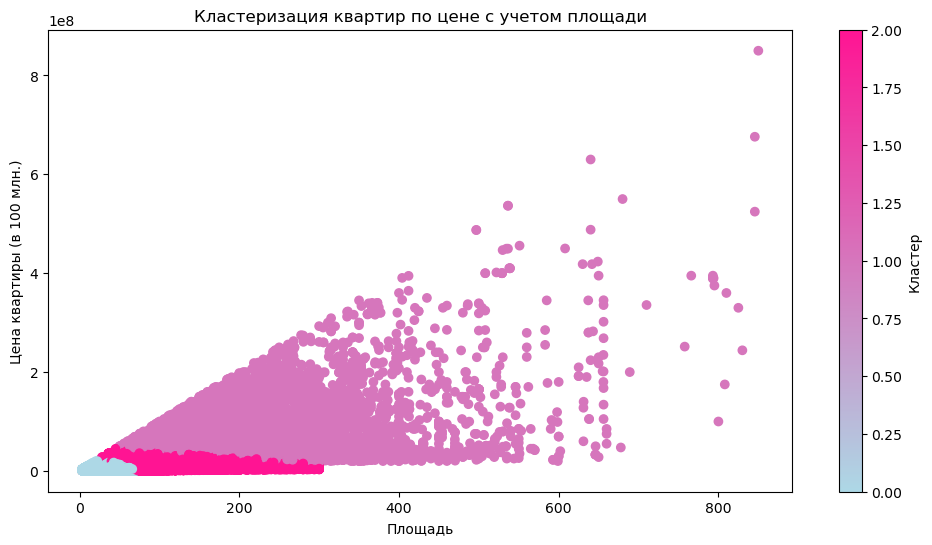

In [49]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

x = df_numeric[['price', 'area']]
scaler = StandardScaler()
scaled_x = scaler.fit_transform(x)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(scaled_x)
df_numeric.loc[:, 'cluster'] = kmeans.labels_

# Визуализация кластеров
plt.figure(figsize=(12, 6))
plt.scatter(df_numeric['area'], df_numeric['price'], c=df_numeric['cluster'], cmap= colors_palette)
plt.xlabel('Площадь')
plt.ylabel('Цена квартиры (в 100 млн.)')
plt.title('Кластеризация квартир по цене с учетом площади')
plt.colorbar(label='Кластер')
plt.show()

In [50]:
columns = df_numeric.columns

agg_functions = {
    'price': 'mean',
    'area': 'mean',
    'kitchen_area': 'mean'
}

for col in columns:
    if col not in agg_functions and col != 'cluster':  # исключаем столбец 'cluster'
        agg_functions[col] = lambda x: x.mode().iloc[0] if not x.mode().empty else None

result = df_numeric.groupby('cluster').agg(agg_functions)
display(result)

,price,area,kitchen_area,building_type,level,levels,rooms,object_type,region_population_rank
cluster,,,,,,,,,
0,3.294708e+06,44.959254,9.782441,1,2,5,1,1,14
1,6.263158e+07,170.853943,25.122891,2,3,7,3,1,0
2,8.244062e+06,83.961482,14.721820,3,2,10,3,1,0


In [51]:
df_numeric['cluster'].value_counts()

cluster
0    3223318
2     973971
1      23102
Name: count, dtype: int64

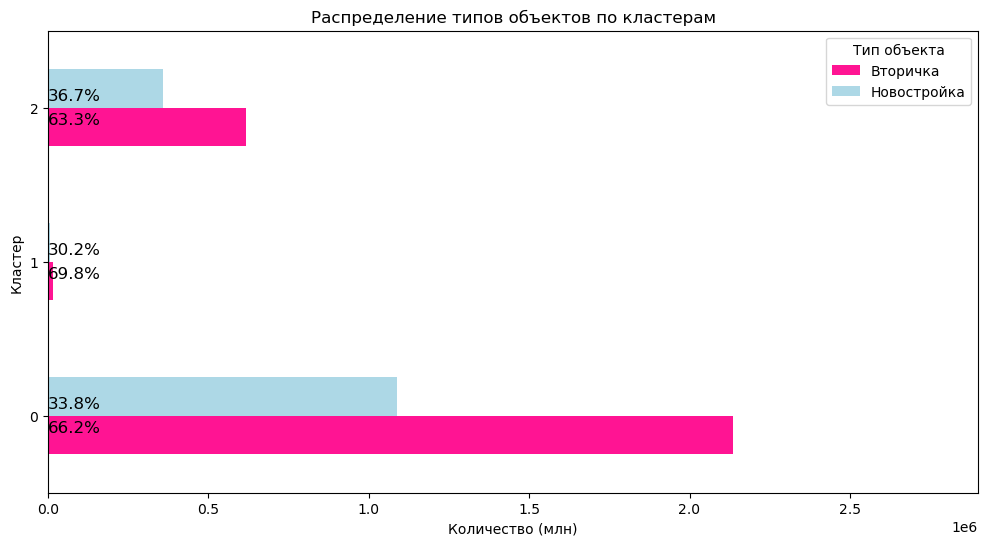

In [52]:
object_type_gb = df_numeric.groupby('cluster')['object_type'].value_counts()
object_type_df = object_type_gb.unstack(fill_value=0)
object_type_df.columns = ['Вторичка', 'Новостройка']  

object_type_percent = df_numeric.groupby('cluster')['object_type'].value_counts(normalize=True) * 100
object_type_percent_df = object_type_percent.unstack(fill_value=0)


# Построение горизонтального графика
ax = object_type_df.plot(kind='barh', figsize=(12, 6), color=['deeppink', 'lightblue'])
plt.title('Распределение типов объектов по кластерам')
plt.xlabel('Количество (млн)')
plt.ylabel('Кластер')
plt.legend(title='Тип объекта', loc='upper right')


for cluster, row in object_type_percent_df.iterrows():
    for idx, value in row.items():  
        x_pos = value + 2 
        y_pos = object_type_percent_df.index.get_loc(cluster) + (list(row.index).index(idx) - 0.5) * 0.15
        plt.text(x_pos, y_pos, f'{value:.1f}%', va='center', ha='left', fontsize=12)

plt.xlim(0,2900000)
plt.show()

<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px; font-weight: bold;">
ВЫВОДЫ:
    </div>
    
    Корреляционный анализ показал, что цена на недвижимость в наибольшей степени зависит от следующих факторов:
     - площадь - связь умеренная прямая. Корреляция 0.49 - Чем больше площадь, тем выше цена
     - площадь кухни - связь умеренная прямая. Корреляция 0.43 - Чем больше площадь кухни, тем выше цена
     - количество комнат - связь умеренная прямая. Корреляция 0.38 - Чем больше комнат, тем выше цена
     - количество этажей в доме - связь умеренная прямая. Корреляция 0.35 - Чем больше этажей, тем выше цена
     - этаж, на котором расположена квартира - связь слабая прямая. Чем выше квартира, тем она дороже 
     - размер населенного пункта (по численности населения) - связь умеренная обратная (мы проранжировали регионы по населению от большего к меньшему). Чем больше населенный пункт, тем дороже квартира
     
     Помимо этого факторы коррелируют между собой:
     area и rooms (0.82) – Площадь и количество комнат также имеют сильную положительную корреляцию. Вероятно, объекты с большей площадью имеют и больше комнат
     kitchen_area и area (0.34) слабая прямая связь
     building_type и level (-0.13) слабая обратная связь
     levels и rooms (-0.15) слабая обратная связь
     Многие пары переменных демонстрируют слабую корреляцию или практически отсутствуют. Это говорит о том, что связь между этими характеристиками не очень сильная.

     Кластеризация позволила сделать следующие выводы:
     1. Наиболее распространены продажи квартир из кластера "0" - назовем их "эконом-класс". Чаще это однокомнатные квартиры, их средняя стоимость 3 млн, средняя площадь - 45 кв.м., чаще всего они расположены в панельных пятиэтажных домах. 66,2% из них представлены на вторичном рынке, на первичном - 33,8%. Интересно еще то, что это квартиры в регионах (мода по рангу региона = 14)
     2. Квартиры кластера "2" - "средний-класс". Это в основном трехкомнатные квартиры в кирпичных домах расположенные на средних этажах высокоэтажных домов. Их средняя площадь составляет 84 кв.м., а средняя цена варьируется около 8 млн. рублей. Из них 32,5% представлены на вторичном рынке (наибольшая доля среди выделенных классов). Большинство таких квартир расположены в крупных городах, больше всего - в Москве 
     3. Квартиры кластера "1" - "премиум-класс". Это самый малочисленный из представленных классов - около 20000 объектов. Это в основном большие  квартиры площадью в среднем 170 кв.м., цена в среднем около 60 млн, расположенные на верхних этажах кирпично-монолитных высокоэтажных домов. В основном эти квартиры расположены в Москве. 

##  Проверка гипотез<a class="anchor" id="sixth-bullet"></a>

In [83]:
df_numeric['price_per_m'] = df_numeric['price'] / df_numeric['area']
df_numeric.head(1)

,price,building_type,level,levels,rooms,area,kitchen_area,object_type,region_population_rank,cluster,price_per_m
0,6050000.0,1,8,10,3,82.6,10.8,1,3,2,73244.552058


In [84]:
# Разделим выборку по цене на две части на основании рынка, на котором представлен объект недвижимости 
primary_market = df_numeric.loc[df_numeric['object_type'] == 11]
secondary_market = df_numeric.loc[df_numeric['object_type'] == 1]
primary_market.shape, secondary_market.shape

((1453205, 11), (2767186, 11))

In [85]:
Q1 = primary_market['price_per_m'].quantile(0.25)
Q3 = primary_market['price_per_m'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

primary_market = primary_market[(primary_market['price_per_m'] >= lower_bound) & (primary_market['price_per_m'] <= upper_bound)]


Q1_secondary = secondary_market['price_per_m'].quantile(0.25)
Q3_secondary = secondary_market['price_per_m'].quantile(0.75)
IQR_secondary = Q3_secondary - Q1_secondary
lower_bound_secondary = Q1_secondary - 1.5 * IQR_secondary
upper_bound_secondary = Q3_secondary + 1.5 * IQR_secondary

secondary_market = secondary_market[(secondary_market['price_per_m'] >= lower_bound_secondary) & (secondary_market['price_per_m'] <= upper_bound_secondary)]

primary_market.shape, secondary_market.shape

((1386951, 11), (2553402, 11))

In [86]:
import random
sample_primary = primary_market['price_per_m']
sample_secondary = secondary_market['price_per_m']
min_size = min(len(sample_primary), len(sample_secondary))

sample_secondary = random.sample(list(sample_secondary),min_size)
sample_secondary = pd.Series(sample_secondary)
sample_primary.shape, sample_secondary.shape

((1386951,), (1386951,))

In [87]:
alpha = 0.05
# если p - value < alpha отвергнем гипотезу
results = st.mannwhitneyu(sample_primary, sample_secondary)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу  о равенстве распределения двух групп')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве распределения двух групп')

p-значение: 0.0
Отвергаем нулевую гипотезу  о равенстве распределения двух групп


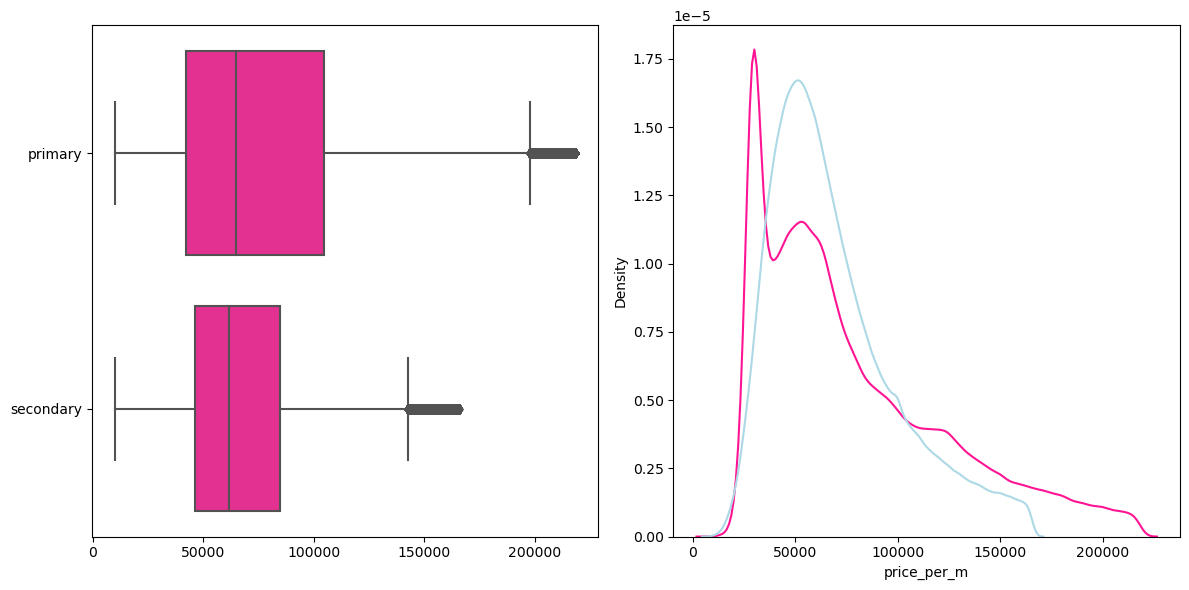

In [91]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
prim_sec = pd.DataFrame({
    'primary': sample_primary,
    'secondary': sample_secondary
})
sns.boxplot(prim_sec,orient='h', color = 'deeppink')

plt.subplot(1, 2, 2)
sns.kdeplot(sample_primary, color = 'deeppink')
sns.kdeplot(sample_secondary, color = 'lightblue')

plt.tight_layout()
plt.show()

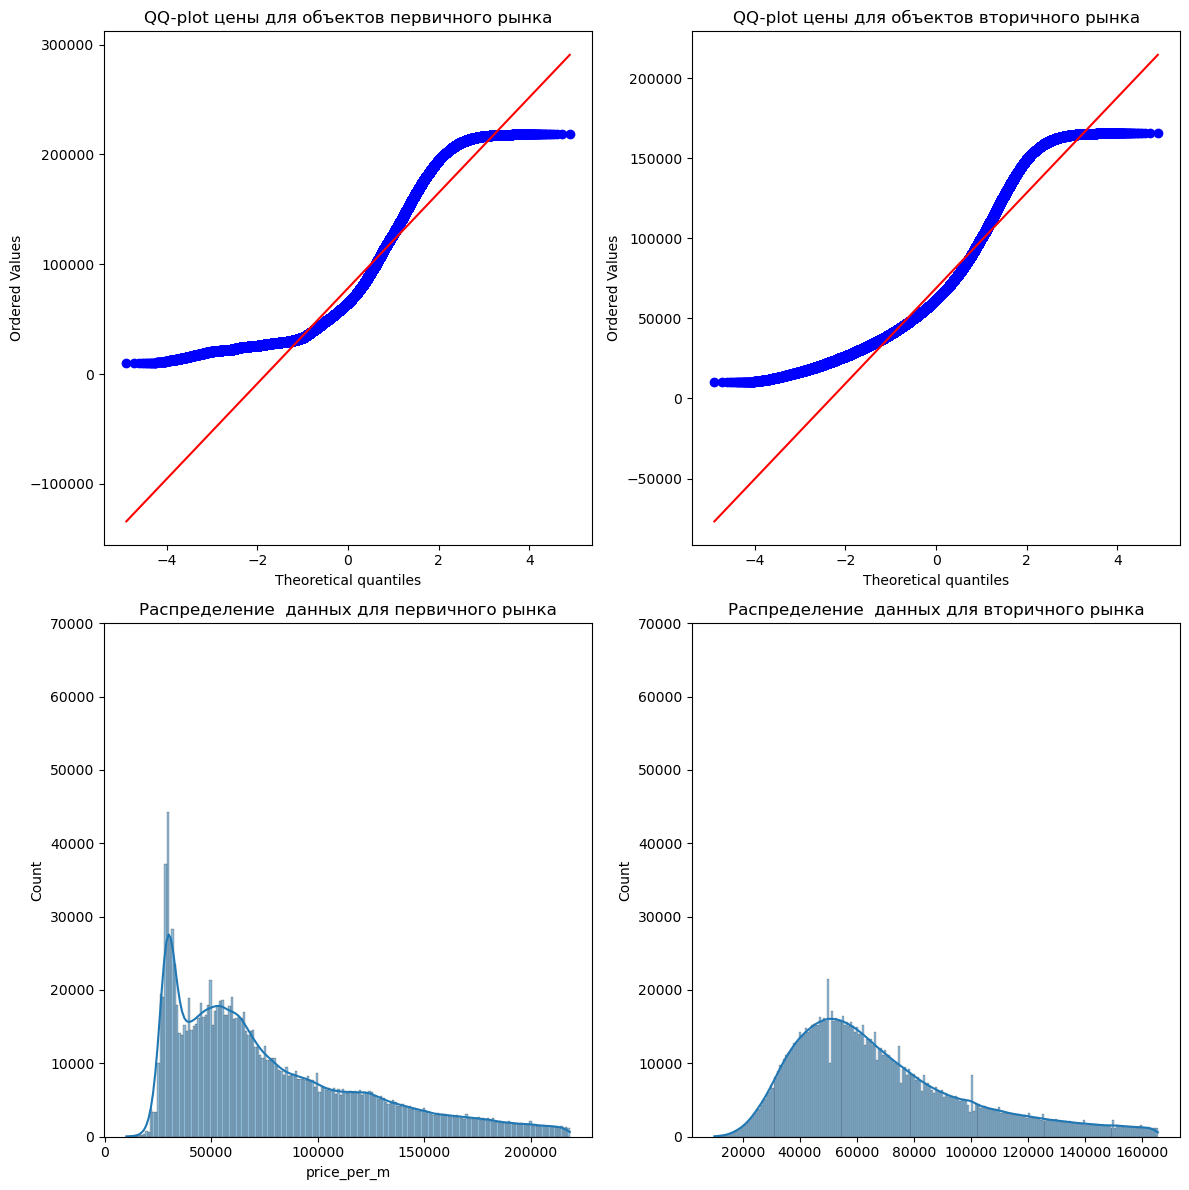

In [59]:
plt.figure(figsize=(12, 12))
plt.subplot(2, 2, 1)
st.probplot(sample_primary, dist='norm', plot=plt);
plt.title('QQ-plot цены для объектов первичного рынка')

plt.subplot(2, 2, 2)
st.probplot(sample_secondary, dist='norm', plot=plt);
plt.title('QQ-plot цены для объектов вторичного рынка')

plt.subplot(2, 2, 3) 
sns.histplot(sample_primary, kde=True)
plt.title("Распределение  данных для первичного рынка")
plt.ylim(0,70000)

plt.subplot(2, 2, 4)  
sns.histplot(sample_secondary, kde=True)
plt.title("Распределение  данных для вторичного рынка")
plt.ylim(0,70000)

plt.tight_layout()
plt.show()

Йео-Джонсон сглаживает выбросы и уменьшает их влияние на анализ, что особенно полезно при работе с сильно скошенными распределениями.

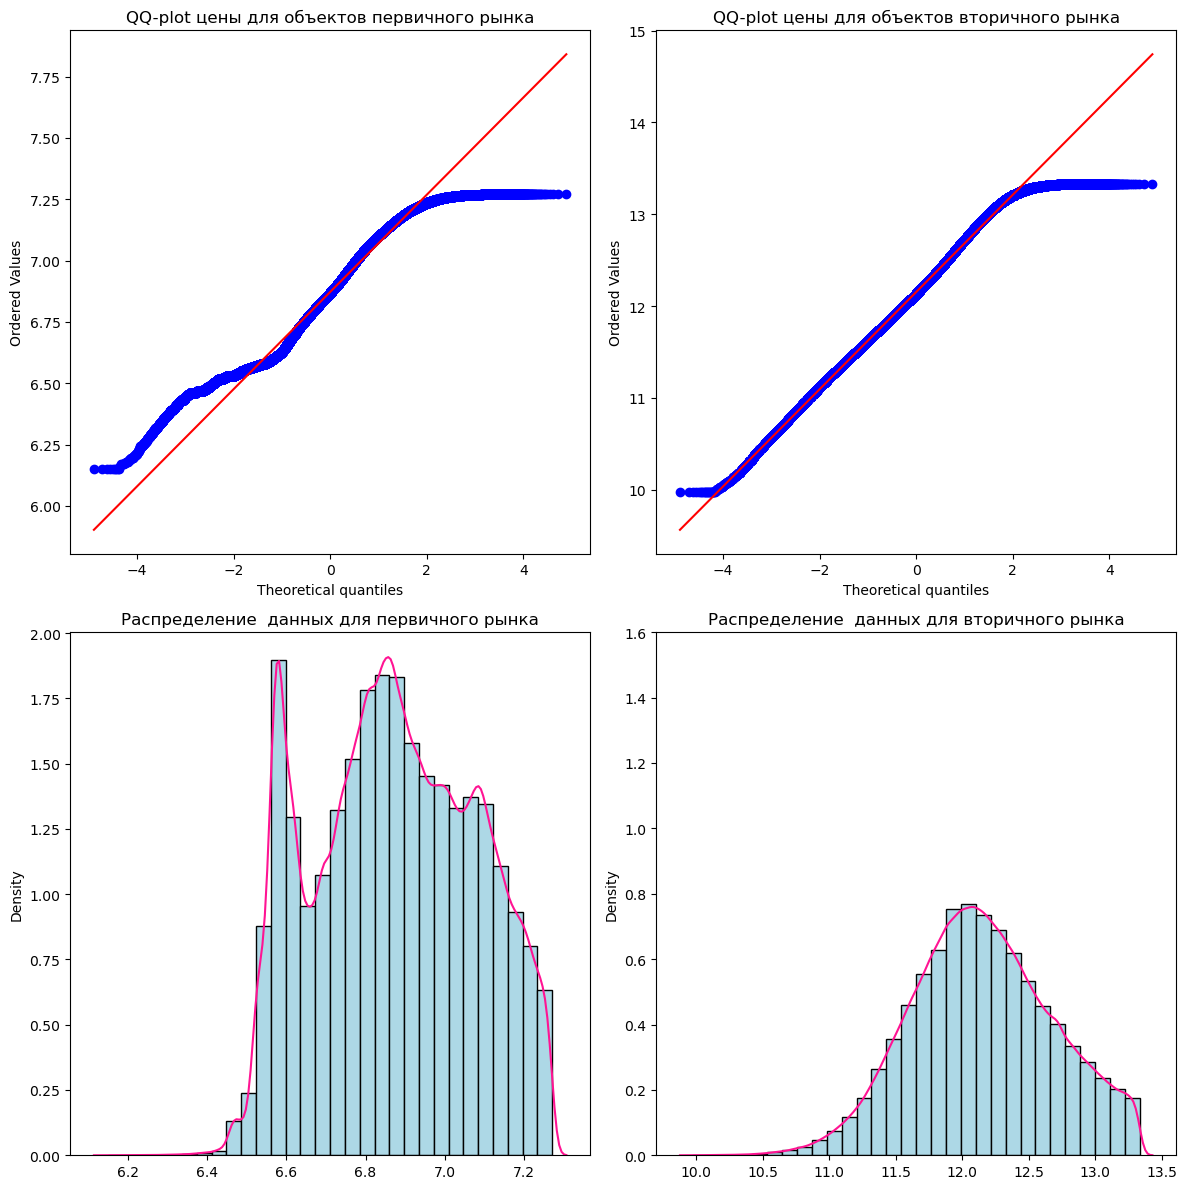

In [60]:
transformer = PowerTransformer(method='yeo-johnson', standardize=False)
sample_primary = sample_primary.values.reshape(-1, 1)
transformed_primary = transformer.fit_transform(sample_primary)
transformed_primary = transformed_primary.flatten() 

sample_secondary = sample_secondary.values.reshape(-1, 1)
transformed_secondary = transformer.fit_transform(sample_secondary)
transformed_secondary = transformed_secondary.flatten() 

plt.figure(figsize=(12, 12))
plt.subplot(2, 2, 1)
st.probplot(transformed_primary, dist='norm', plot=plt)
plt.title('QQ-plot цены для объектов первичного рынка')

plt.subplot(2, 2, 2)
st.probplot(transformed_secondary, dist='norm', plot=plt);
plt.title('QQ-plot цены для объектов вторичного рынка')

plt.subplot(2, 2, 3)
plt.hist(transformed_primary, bins=30, color='lightblue', edgecolor='black', density=True)  #добавляем density=True для нормализации
sns.kdeplot(transformed_primary, color='deeppink')  #добавляем линию KDE для распределения
plt.title("Распределение  данных для первичного рынка")

plt.subplot(2, 2, 4)  
plt.hist(transformed_secondary, bins=30, color='lightblue', edgecolor='black', density=True)  #добавляем density=True для нормализации
sns.kdeplot(transformed_secondary, color='deeppink')  #добавляем линию KDE для распределения
plt.ylim(0,1.6)
plt.title("Распределение  данных для вторичного рынка")

plt.tight_layout()
plt.show()

In [61]:
alpha = 0.05

results = st.ttest_ind(transformed_primary, transformed_secondary)

print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу о равенстве средних цен для объектов первичного и вторичного рынка')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве средних цен для объектов первичного и вторичного рынка')

p-значение: 0.0
Отвергаем нулевую гипотезу о равенстве средних цен для объектов первичного и вторичного рынка


In [62]:
alpha = 0.05
# если p - value < alpha отвергнем гипотезу
results = st.mannwhitneyu(transformed_primary, transformed_secondary)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу  о равенстве распределения двух групп')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве распределения двух групп')

p-значение: 0.0
Отвергаем нулевую гипотезу  о равенстве распределения двух групп


In [80]:
prim = primary_market['price_per_m'].mean().round(2)
sec = secondary_market['price_per_m'].mean().round(2)
print(f'Средняя цена за квадратный метр объектов недвижимости на первичном рынке: {prim} рублей')
print(f'Средняя цена за квадратный метр объектов недвижимости на вторичном рынке: {sec} рублей')

Средняя цена за квадратный метр объектов недвижимости на первичном рынке: 78333.35 рублей
Средняя цена за квадратный метр объектов недвижимости на вторичном рынке: 68877.01 рублей


In [81]:
prim = np.median(primary_market['price_per_m']).round(2)
sec = np.median(secondary_market['price_per_m']).round(2)
print(f'Медианная цена за квадратный метр объектов недвижимости на первичном рынке: {prim} рублей')
print(f'Медианная цена за квадратный метр объектов недвижимости на вторичном рынке: {sec} рублей')

Медианная цена за квадратный метр объектов недвижимости на первичном рынке: 64917.13 рублей
Медианная цена за квадратный метр объектов недвижимости на вторичном рынке: 61650.0 рублей


<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px;">
    ВЫВОДЫ. 
        </div>
        
        Учитывая p-value = 0 как в параметрических, так и в непараметрических тестах, при условии ненормальности распределений данных и визуальной подтвержденности различия средних, мы имеем сильные доказательства статистически значимого различия средних цен на первичном и вторичном рынках недвижимости. Несмотря на ненормальность распределений, результаты непараметрических тестов подтверждают вывод, полученный параметрическими тестами (хотя и некорректно интерпретируемый в виду ненормальности). Визуализация дополнительно поддерживает этот вывод.

<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px;">
    ГИПОТЕЗА 2. 
        </div>
        
  `Нулевая гипотеза H0`: средняя цена за квадратный метр квартир в высокоэтажных домах и квартир в малоэтажных домах не отличается 
 
`Альтернативная гипотеза H1`: средняя цена за квадратный метр квартир в высокоэтажных домах и квартир в малоэтажных домах  отличается 

In [97]:
high_rise = df_numeric.loc[df_numeric['levels'] >= 10, 'price_per_m']
low_rise = df_numeric.loc[df_numeric['levels'] < 10, 'price_per_m']
high_rise.shape, low_rise.shape

((2464324,), (1756067,))

In [98]:
Q1 = high_rise.quantile(0.25)
Q3 = high_rise.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
high_rise = high_rise[(high_rise>= lower_bound) & (high_rise <= upper_bound)]


Q1_low = low_rise.quantile(0.25)
Q3_low = low_rise.quantile(0.75)
IQR_low = Q3_low - Q1_low
lower_bound_low = Q1_low - 1.5 * IQR_low
upper_bound_low = Q3_low + 1.5 * IQR_low
low_rise = low_rise[(low_rise >= lower_bound_low) & (low_rise <= upper_bound_low)]

high_rise.shape, low_rise.shape

# удалилось всего 6% и 9% соответсвенно 

((2336523,), (1607722,))

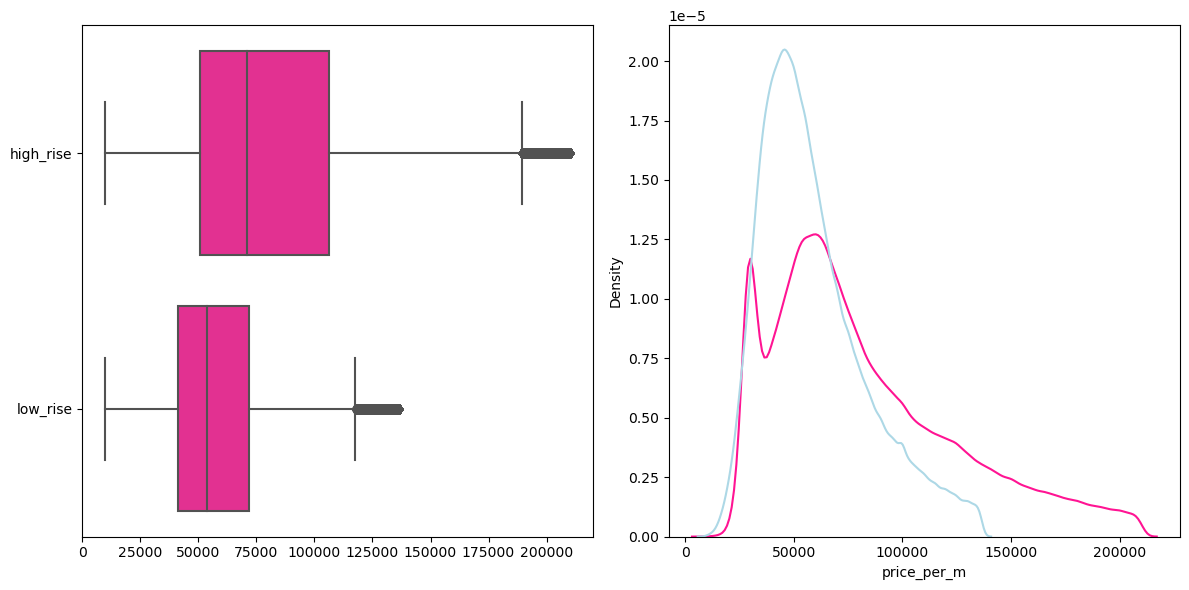

In [99]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
prim_sec = pd.DataFrame({
    'high_rise': high_rise,
    'low_rise': low_rise
})
sns.boxplot(prim_sec,orient='h', color = 'deeppink')

plt.subplot(1, 2, 2)
sns.kdeplot(high_rise, color = 'deeppink')
sns.kdeplot(low_rise, color = 'lightblue')

plt.tight_layout()
plt.show()

In [100]:
alpha = 0.05
results = st.mannwhitneyu(high_rise,low_rise)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах')

p-значение: 0.0
Отвергаем нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах


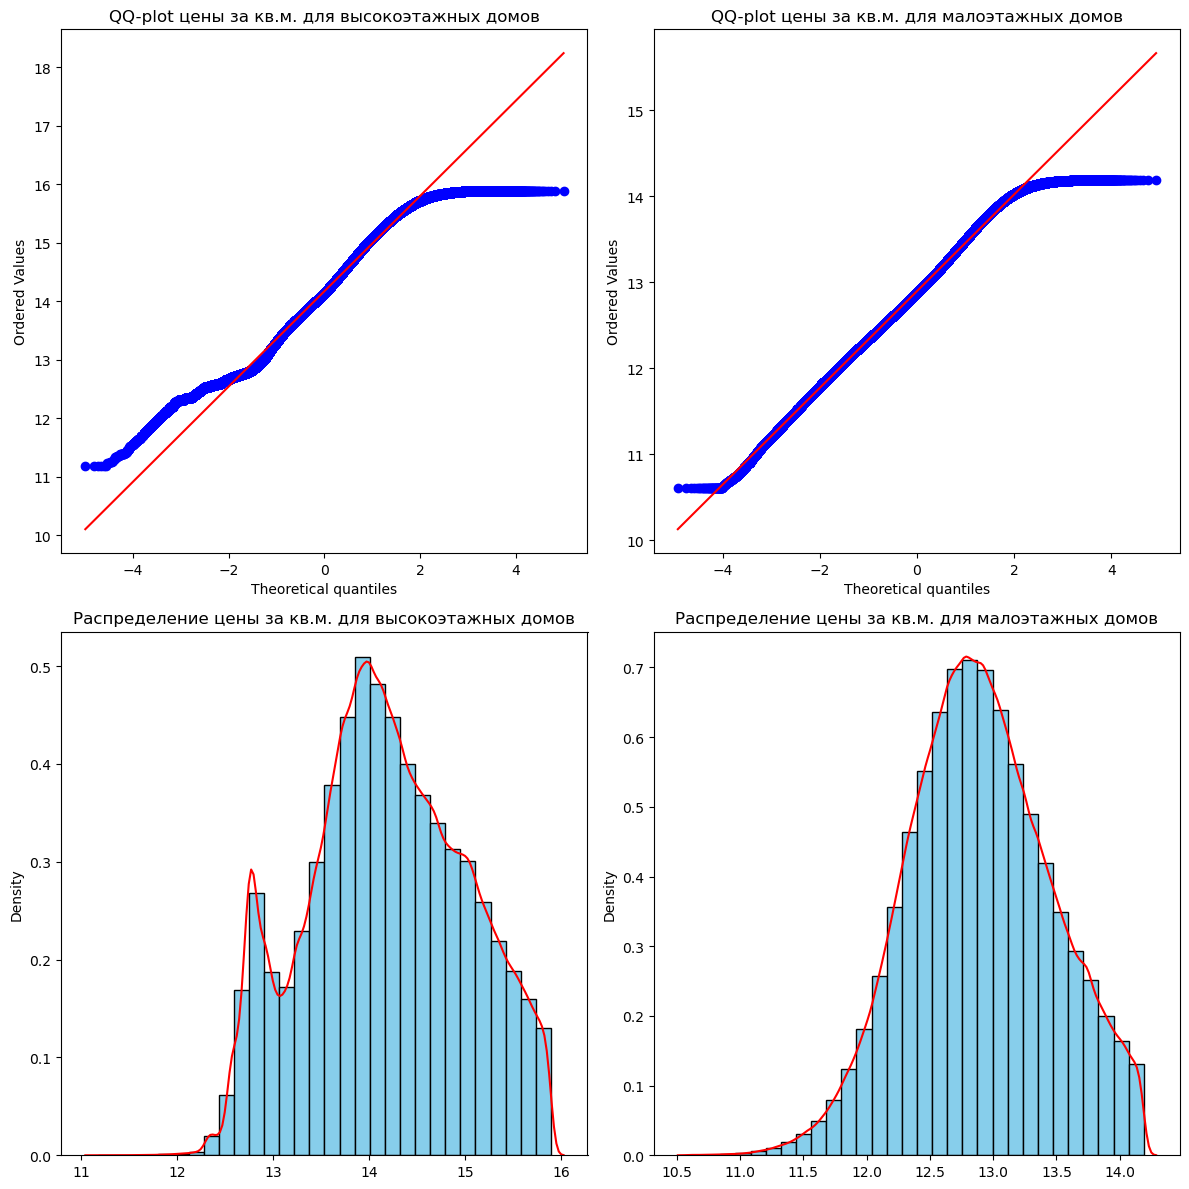

In [69]:
transformer = PowerTransformer(method='yeo-johnson', standardize=False)
high_rise = high_rise.values.reshape(-1, 1)
transformed_price_high_rise = transformer.fit_transform(high_rise)
transformed_price_high_rise = transformed_price_high_rise.flatten() 

low_rise = low_rise.values.reshape(-1, 1)
transformed_price_low_rise = transformer.fit_transform(low_rise)
transformed_price_low_rise = transformed_price_low_rise.flatten() 

plt.figure(figsize=(12, 12))
plt.subplot(2, 2, 1)
st.probplot(transformed_price_high_rise, dist='norm', plot=plt);
plt.title('QQ-plot цены за кв.м. для высокоэтажных домов')

plt.subplot(2, 2, 2)
st.probplot(transformed_price_low_rise, dist='norm', plot=plt);
plt.title('QQ-plot цены за кв.м. для малоэтажных домов')

plt.subplot(2, 2, 3)
plt.hist(transformed_price_high_rise, bins=30, color='skyblue', edgecolor='black', density=True)  #добавляем density=True для нормализации
sns.kdeplot(transformed_price_high_rise, color='red')  #добавляем линию KDE для распределения
plt.title("Распределение цены за кв.м. для высокоэтажных домов")

plt.subplot(2, 2, 4)  
plt.hist(transformed_price_low_rise, bins=30, color='skyblue', edgecolor='black', density=True)  #добавляем density=True для нормализации
sns.kdeplot(transformed_price_low_rise, color='red')  #добавляем линию KDE для распределения
plt.title("Распределение цены за кв.м. для малоэтажных домов")

plt.tight_layout()
plt.show()

In [70]:
alpha = 0.05
results = st.mannwhitneyu(transformed_price_high_rise,transformed_price_low_rise)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах')

p-значение: 0.0
Отвергаем нулевую гипотезу о равенстве распределений цен за кв.м. в высотных и малоэтажных домах


In [94]:
alpha = 0.05

results = st.ttest_ind(transformed_price_high_rise,transformed_price_low_rise)

print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу о равенстве средних цен для объектов в высотных и малоэтажных домах')
else:
    print('Не получилось отвергнуть нулевую гипотезу о равенстве средних цен для объектов в высотных и малоэтажных домах')

p-значение: 0.0
Отвергаем нулевую гипотезу о равенстве средних цен для объектов в высотных и малоэтажных домах


In [96]:
high_rise = df_numeric.loc[df_numeric['levels'] >= 10, 'price_per_m']
low_rise = df_numeric.loc[df_numeric['levels'] < 10, 'price_per_m']

high_mean = round(high_rise.mean(),2)
low_mean = round(low_rise.mean(), 2)

print(f'Средняя цена за квадратный метр объектов недвижимости на первичном рынке: {high_mean} рублей')
print(f'Средняя цена за квадратный метр объектов недвижимости на вторичном рынке: {low_mean} рублей')

Средняя цена за квадратный метр объектов недвижимости на первичном рынке: 92443.73 рублей
Средняя цена за квадратный метр объектов недвижимости на вторичном рынке: 73003.62 рублей


<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px;">
    ВЫВОДЫ. 
        </div>
        
        Результаты анализа, включая как параметрические, так и непараметрические тесты (p-value = 0 для обоих типов), несмотря на ненормальное распределение данных, демонстрируют статистически значимое различие в средних ценах за квадратный метр в высокоэтажных и малоэтажных домах. Визуальный анализ данных подтверждает наличие этого различия

## [Вернуться к навигации](#Навигация)

##  Прогноз цен на недвижимость<a class="anchor" id="seventh-bullet"></a>

In [72]:
df_numeric.head(1)

,price,building_type,level,levels,rooms,area,kitchen_area,object_type,region_population_rank,cluster,price_per_m
0,6050000.0,1,8,10,3,82.6,10.8,1,3,2,73244.552058


In [110]:
y = df_numeric['price']
x = df_numeric.iloc[:,1:-2]


#разделяем данные на обучающую и валидационную выборку с random_state=13
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=13)

model = LinearRegression()

scaler = StandardScaler()
x_train_st = scaler.fit_transform(x_train)
model.fit(x_train_st,y_train)
x_test_st = scaler.transform(x_test)
predictions = model.predict(x_test_st)
y_pred = model.predict(x_test_st)
print(model.coef_, model.intercept_)
print(r2_score(y_test, y_pred))

[  128415.45041306    86290.93205974   553800.03882648 -1089037.94267181
  4196780.36101821   215732.44387615  -307964.61887553 -1073966.73666818] 4762799.926942468
0.3698017457884505


In [103]:
from sklearn.metrics import  mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

y_pred = model.predict(x_test_st)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Среднеквадратическая ошибка (MSE):", mse)
print("Среднеквадратическая ошибка (RMSE):", rmse)
print("Средняя абсолютная ошибка (MAE):", mae)
print("Средняя абсолютная ошибка  (MAPE):", mape)
print("Коэффициент детерминации (R^2):", r2)

Среднеквадратическая ошибка (MSE): 26531119130645.223
Среднеквадратическая ошибка (RMSE): 5150836.740826215
Средняя абсолютная ошибка (MAE): 2500695.5612653214
Средняя абсолютная ошибка  (MAPE): 0.6638396726622957
Коэффициент детерминации (R^2): 0.36831255778160676


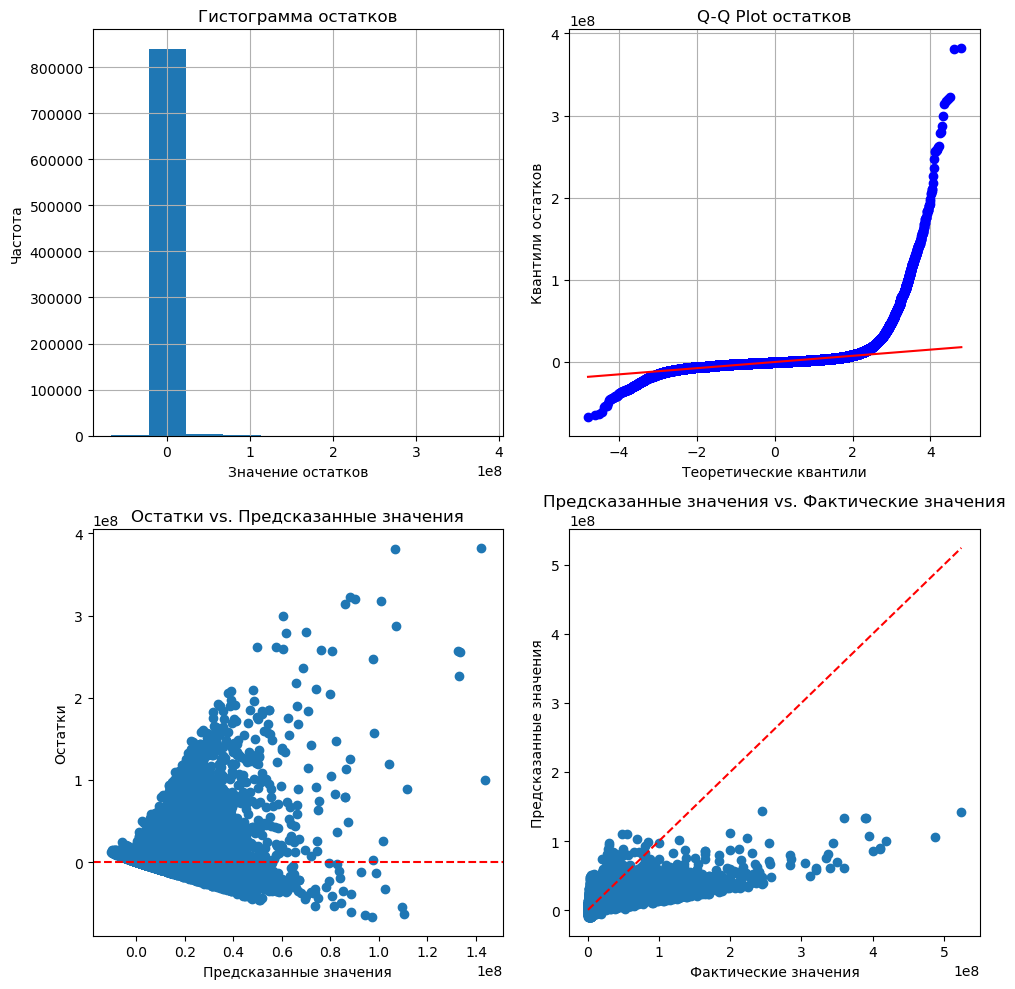

In [104]:
import statsmodels.api as sm

# Получение остатков модели
residuals = y_test - predictions

# Расчет стандартизированных остатков
stand_residuals = (residuals - np.mean(residuals)) / np.std(residuals)
plt.subplots(figsize=(10, 10))


# Распределение остатков
plt.subplot(2, 2, 1)
plt.hist(residuals)
plt.xlabel('Значение остатков')
plt.ylabel('Частота')
plt.title('Гистограмма остатков')
plt.grid(True)


# График остатков vs. предсказанных значений
plt.subplot(2, 2, 2)
st.probplot(residuals, dist='norm', plot=plt)
plt.xlabel('Теоретические квантили')
plt.ylabel('Квантили остатков')
plt.title('Q-Q Plot остатков')
plt.grid(True)

#График остатков относительно прогноза
plt.subplot(2, 2, 3)
plt.scatter(predictions, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Остатки vs. Предсказанные значения')

# Предсказанные и фактические значения
plt.subplot(2, 2, 4)
plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],  "k--", color='r')
plt.xlabel('Фактические значения')
plt.ylabel('Предсказанные значения')
plt.title('Предсказанные значения vs. Фактические значения')

plt.tight_layout()
plt.show()

<div style="background-color: lavender; padding: 10px; border-radius: 5px; font-family: Arial, sans-serif; font-size: 16px;">
    ВЫВОДЫ. 
        </div>
         
         Высокие значения ошибок: MSE и RMSE  указывают на значительные отклонения предсказанных значений от фактических. MAE также показывает существенную среднюю абсолютную ошибку. Эти большие значения ошибок свидетельствуют о плохой точности модели.
         Высокий MAPE указывает на то, что в среднем отклоняются на 66% от фактических значений. Это очень высокий показатель, свидетельствующий о низкой точности прогнозов. 
         Коэффициент детерминации  очень низкий. Это означает, что модель объясняет только около 37% дисперсии зависимой переменной. Остальные 63% дисперсии остаются необъясненными, что указывает на значительное несоответствие между предсказаниями модели и фактическими данными.
         Графики подтверждают выводы, полученные из метрик: гистограмма остатков не похожа на нормальное распределение, Q-Q plot четко показывает отклонение от нормальности, графики указывают на гетероскедастичность остатков, и показывают, что модель систематически недооценивает большие значения и переоценивает маленькие.
         В целом, модель демонстрирует крайне неудовлетворительное качество предсказания.

In [118]:
y = df_numeric['price']
x = df_numeric[['level','area','region_population_rank']]


#разделяем данные на обучающую и валидационную выборку с random_state=13
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=13)

model = LinearRegression()

scaler = StandardScaler()
x_train_st = scaler.fit_transform(x_train)
model.fit(x_train_st,y_train)
x_test_st = scaler.transform(x_test)
predictions = model.predict(x_test_st)
y_pred = model.predict(x_test_st)
print(model.coef_, model.intercept_)
print(r2_score(y_test, y_pred))

[  480275.33134411  3540926.59471988 -1185883.0919981 ] 4762799.92694247
0.34813468810187687


## [Вернуться к навигации](#Навигация)